In [9]:
import pandas as pd  # WHY: load our processed CSV datasets
import joblib  # WHY: reload the scaler fitted during preprocessing

X_train = pd.read_csv("processed_data/X_train.csv")
X_val = pd.read_csv("processed_data/X_val.csv")
X_test = pd.read_csv("processed_data/X_test.csv")

y_train = pd.read_csv("processed_data/y_train.csv").squeeze()
y_val = pd.read_csv("processed_data/y_val.csv").squeeze()
y_test = pd.read_csv("processed_data/y_test.csv").squeeze()

scaler = joblib.load("processed_data/price_scaler.pkl")  # WHY: reuse training scaler

X_train_scaled = scaler.transform(X_train)
X_val_scaled = scaler.transform(X_val)
X_test_scaled = scaler.transform(X_test)

In [10]:
print("Train:", X_train_scaled.shape, y_train.shape)
print("Validation:", X_val_scaled.shape, y_val.shape)
print("Test:", X_test_scaled.shape, y_test.shape)

print("Train mean:", X_train_scaled.mean())
print("Train std:", X_train_scaled.std())

Train: (24427, 23) (24427,)
Validation: (5234, 23) (5234,)
Test: (5235, 23) (5235,)
Train mean: 4.047083954555491e-18
Train std: 1.0


In [11]:
import tensorflow as tf  # WHY: provides Keras for building the neural network

model = tf.keras.Sequential([
    tf.keras.layers.Input(shape=(23,)),  # WHY: our dataset has exactly 23 input features
    tf.keras.layers.Dense(128, activation="relu"),  # WHY: learn nonlinear feature relationships
    tf.keras.layers.Dense(64, activation="relu"),  # WHY: combine higher-level learned patterns
    tf.keras.layers.Dense(1, activation="linear")  # WHY: electricity price is continuous
])

model.compile(
    optimizer=tf.keras.optimizers.Adam(learning_rate=0.001),  # WHY: stable baseline optimizer
    loss="mse",  # WHY: penalize large price prediction errors
    metrics=["mae"]  # WHY: track interpretable average absolute error
)

model.summary()  # WHY: verify architecture and trainable parameter count

Model: "sequential"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ dense (Dense)                   │ (None, 128)            │         3,072 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_1 (Dense)                 │ (None, 64)             │         8,256 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_2 (Dense)                 │ (None, 1)              │            65 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 11,393 (44.50 KB)

 Trainable params: 11,393 (44.50 KB)

 Non-trainable params: 0 (0.00 B)

In [12]:
early_stop = tf.keras.callbacks.EarlyStopping(
    monitor="val_loss",  # WHY: watch performance on unseen validation data
    patience=10,  # WHY: stop if validation loss fails to improve for 10 epochs
    restore_best_weights=True  # WHY: keep the best model, not the final epoch
)

history = model.fit(
    X_train_scaled, y_train,  # WHY: data used to update ANN weights
    validation_data=(X_val_scaled, y_val),  # WHY: detect overfitting during training
    epochs=100,  # WHY: maximum training duration; early stopping can finish sooner
    batch_size=32,  # WHY: update weights after every 32 training samples
    callbacks=[early_stop],  # WHY: automatically stop when learning stops improving
    verbose=1  # WHY: show epoch-by-epoch training progress
)

Epoch 1/100
764/764 ━━━━━━━━━━━━━━━━━━━━ 1s 1ms/step - loss: 281.8898 - mae: 9.5315 - val_loss: 25.6280 - val_mae: 3.7619
Epoch 2/100
764/764 ━━━━━━━━━━━━━━━━━━━━ 1s 1ms/step - loss: 11.9404 - mae: 2.5906 - val_loss: 14.7093 - val_mae: 2.7663
Epoch 3/100
764/764 ━━━━━━━━━━━━━━━━━━━━ 1s 1ms/step - loss: 7.7584 - mae: 2.0733 - val_loss: 10.2906 - val_mae: 2.3108
Epoch 4/100
764/764 ━━━━━━━━━━━━━━━━━━━━ 2s 3ms/step - loss: 6.5333 - mae: 1.8962 - val_loss: 9.7491 - val_mae: 2.2182
Epoch 5/100
764/764 ━━━━━━━━━━━━━━━━━━━━ 2s 3ms/step - loss: 6.0383 - mae: 1.8235 - val_loss: 9.2784 - val_mae: 2.1645
Epoch 6/100
764/764 ━━━━━━━━━━━━━━━━━━━━ 2s 3ms/step - loss: 5.8130 - mae: 1.7849 - val_loss: 9.7278 - val_mae: 2.2287
Epoch 7/100
764/764 ━━━━━━━━━━━━━━━━━━━━ 2s 3ms/step - loss: 5.5127 - mae: 1.7393 - val_loss: 9.0383 - val_mae: 2.1504
Epoch 8/100
764/764 ━━━━━━━━━━━━━━━━━━━━ 3s 3ms/step - loss: 5.3457 - mae: 1.7104 - val_loss: 8.4629 - val_mae: 2.0471
Epoch 9/100
764/764 ━━━━━━━━━━━━━━━━━━━━ 2

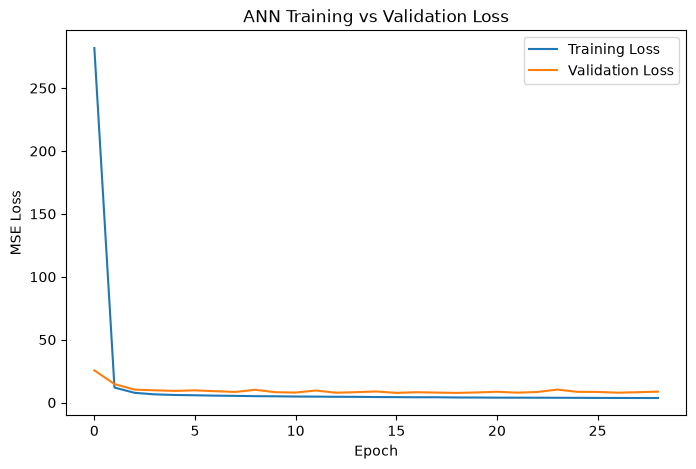

In [13]:
import matplotlib.pyplot as plt  # WHY: visualize learning behaviour

plt.figure(figsize=(8, 5))
plt.plot(history.history["loss"], label="Training Loss")
plt.plot(history.history["val_loss"], label="Validation Loss")

plt.xlabel("Epoch")
plt.ylabel("MSE Loss")
plt.title("ANN Training vs Validation Loss")
plt.legend()
plt.show()

In [14]:
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score  # WHY: regression metrics

y_pred = model.predict(X_test_scaled).flatten()  # WHY: predict completely unseen test prices

mae = mean_absolute_error(y_test, y_pred)  # WHY: average absolute forecasting error
rmse = mean_squared_error(y_test, y_pred) ** 0.5  # WHY: penalizes large errors more strongly
mape = np.mean(np.abs((y_test - y_pred) / y_test)) * 100  # WHY: percentage error
r2 = r2_score(y_test, y_pred)  # WHY: measures explained variation

best_epoch = np.argmin(history.history["val_loss"]) + 1  # WHY: locate best validation model

print("Best epoch:", best_epoch)
print(f"MAE  : {mae:.4f}")
print(f"RMSE : {rmse:.4f}")
print(f"MAPE : {mape:.2f}%")
print(f"R²   : {r2:.4f}")

164/164 ━━━━━━━━━━━━━━━━━━━━ 0s 572us/step
Best epoch: 19
MAE  : 1.4198
RMSE : 1.8837
MAPE : 2.09%
R²   : 0.9434


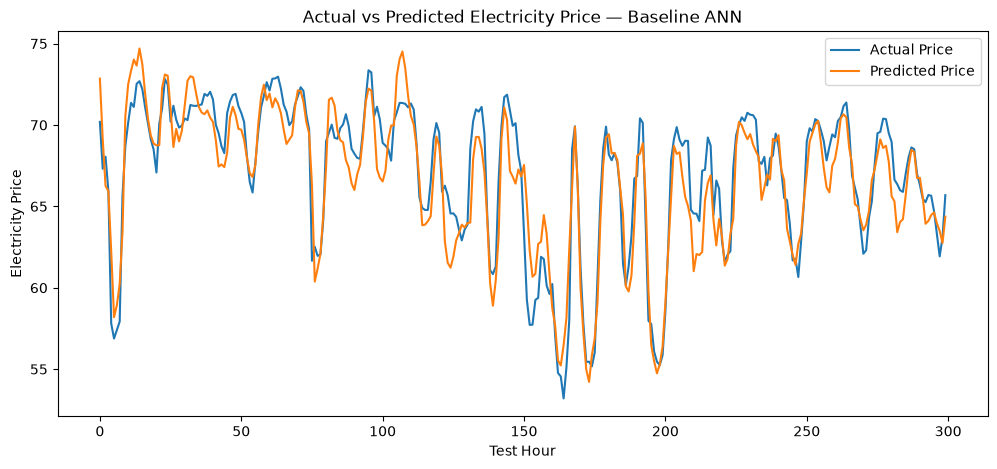

In [15]:
plt.figure(figsize=(12, 5))

plt.plot(y_test[:300].to_numpy(), label="Actual Price")  # WHY: show real price movement
plt.plot(y_pred[:300], label="Predicted Price")  # WHY: visually compare ANN forecasting

plt.xlabel("Test Hour")
plt.ylabel("Electricity Price")
plt.title("Actual vs Predicted Electricity Price — Baseline ANN")
plt.legend()
plt.show()

In [17]:
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score

def evaluate_baseline(name, actual, prediction):  # WHY: evaluate every baseline identically
    mae = mean_absolute_error(actual, prediction)
    rmse = mean_squared_error(actual, prediction) ** 0.5
    r2 = r2_score(actual, prediction)

    print(f"{name}")
    print(f"MAE  : {mae:.4f}")
    print(f"RMSE : {rmse:.4f}")
    print(f"R²   : {r2:.4f}")
    print("-" * 30)

In [18]:
day_ahead_pred = X_test["price day ahead"].to_numpy()  # WHY: market forecast baseline

lag1_pred = X_test["price_lag_1"].to_numpy()  # WHY: assume next price equals previous hour

lag24_pred = X_test["price_lag_24"].to_numpy()  # WHY: assume today's price repeats yesterday

actual = y_test.to_numpy()  # WHY: common ground truth for every baseline

evaluate_baseline("Day-Ahead Price", actual, day_ahead_pred)
evaluate_baseline("1-Hour Persistence", actual, lag1_pred)
evaluate_baseline("24-Hour Persistence", actual, lag24_pred)
evaluate_baseline("ANN Baseline", actual, y_pred)

Day-Ahead Price
MAE  : 8.6009
RMSE : 11.9728
R²   : -1.2883
------------------------------
1-Hour Persistence
MAE  : 1.9724
RMSE : 2.8774
R²   : 0.8678
------------------------------
24-Hour Persistence
MAE  : 3.9347
RMSE : 5.4200
R²   : 0.5311
------------------------------
ANN Baseline
MAE  : 1.4198
RMSE : 1.8837
R²   : 0.9434
------------------------------


Mean residual: 0.07014336479063132
Largest overprediction: -11.240372161865231
Largest underprediction: 13.025927734375003


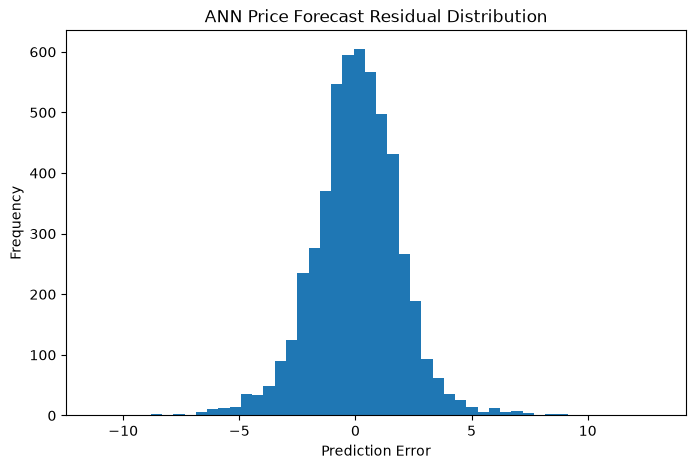

In [19]:
residuals = y_test.to_numpy() - y_pred  # WHY: measure error for every test prediction

print("Mean residual:", residuals.mean())  # WHY: detect systematic over/under prediction
print("Largest overprediction:", residuals.min())  # WHY: inspect worst high prediction
print("Largest underprediction:", residuals.max())  # WHY: inspect worst low prediction

plt.figure(figsize=(8, 5))
plt.hist(residuals, bins=50)  # WHY: inspect the distribution of prediction errors
plt.xlabel("Prediction Error")
plt.ylabel("Frequency")
plt.title("ANN Price Forecast Residual Distribution")
plt.show()

In [20]:
small_model = tf.keras.Sequential([
    tf.keras.layers.Input(shape=(23,)),  # WHY: same features as baseline
    tf.keras.layers.Dense(64, activation="relu"),  # WHY: test lower model capacity
    tf.keras.layers.Dense(32, activation="relu"),  # WHY: smaller second representation
    tf.keras.layers.Dense(1, activation="linear")  # WHY: continuous price output
])

small_model.compile(
    optimizer=tf.keras.optimizers.Adam(learning_rate=0.001),  # WHY: hold LR constant
    loss="mse",  # WHY: same objective for fair comparison
    metrics=["mae"]  # WHY: same training metric as baseline
)

In [21]:
small_history = small_model.fit(
    X_train_scaled, y_train,  # WHY: identical training dataset
    validation_data=(X_val_scaled, y_val),  # WHY: identical validation dataset
    epochs=100,  # WHY: same maximum as baseline
    batch_size=32,  # WHY: hold batch size constant
    callbacks=[tf.keras.callbacks.EarlyStopping(
        monitor="val_loss", patience=10, restore_best_weights=True
    )],  # WHY: identical stopping rule
    verbose=1
)

Epoch 1/100
764/764 ━━━━━━━━━━━━━━━━━━━━ 1s 1ms/step - loss: 452.2306 - mae: 13.5315 - val_loss: 37.4878 - val_mae: 4.6884
Epoch 2/100
764/764 ━━━━━━━━━━━━━━━━━━━━ 1s 969us/step - loss: 16.6796 - mae: 3.0824 - val_loss: 19.4410 - val_mae: 3.2526
Epoch 3/100
764/764 ━━━━━━━━━━━━━━━━━━━━ 1s 999us/step - loss: 10.4235 - mae: 2.4171 - val_loss: 13.9718 - val_mae: 2.6867
Epoch 4/100
764/764 ━━━━━━━━━━━━━━━━━━━━ 1s 997us/step - loss: 8.3143 - mae: 2.1470 - val_loss: 12.0554 - val_mae: 2.5133
Epoch 5/100
764/764 ━━━━━━━━━━━━━━━━━━━━ 1s 1ms/step - loss: 7.2121 - mae: 1.9974 - val_loss: 10.1476 - val_mae: 2.3054
Epoch 6/100
764/764 ━━━━━━━━━━━━━━━━━━━━ 1s 957us/step - loss: 6.5939 - mae: 1.9074 - val_loss: 9.7100 - val_mae: 2.2414
Epoch 7/100
764/764 ━━━━━━━━━━━━━━━━━━━━ 1s 974us/step - loss: 6.2562 - mae: 1.8565 - val_loss: 9.3304 - val_mae: 2.1634
Epoch 8/100
764/764 ━━━━━━━━━━━━━━━━━━━━ 1s 961us/step - loss: 6.0229 - mae: 1.8254 - val_loss: 8.7610 - val_mae: 2.1020
Epoch 9/100
764/764 ━━━━━━

In [22]:
small_pred = small_model.predict(X_test_scaled).flatten()  # WHY: same unseen test set

small_mae = mean_absolute_error(y_test, small_pred)
small_rmse = mean_squared_error(y_test, small_pred) ** 0.5
small_r2 = r2_score(y_test, small_pred)

print(f"MAE  : {small_mae:.4f}")
print(f"RMSE : {small_rmse:.4f}")
print(f"R²   : {small_r2:.4f}")

164/164 ━━━━━━━━━━━━━━━━━━━━ 0s 620us/step
MAE  : 1.4607
RMSE : 1.9541
R²   : 0.9390


In [23]:
large_model = tf.keras.Sequential([
    tf.keras.layers.Input(shape=(23,)),  # WHY: same 23 forecasting features
    tf.keras.layers.Dense(256, activation="relu"),  # WHY: test higher model capacity
    tf.keras.layers.Dense(128, activation="relu"),  # WHY: learn richer feature interactions
    tf.keras.layers.Dense(1, activation="linear")  # WHY: predict continuous price
])

large_model.compile(
    optimizer=tf.keras.optimizers.Adam(learning_rate=0.001),  # WHY: keep LR unchanged
    loss="mse",  # WHY: same loss ensures fair comparison
    metrics=["mae"]  # WHY: track absolute forecasting error
)

In [24]:
large_history = large_model.fit(
    X_train_scaled, y_train,  # WHY: use identical training observations
    validation_data=(X_val_scaled, y_val),  # WHY: identical validation period
    epochs=100,  # WHY: same maximum training duration
    batch_size=32,  # WHY: hold batch behaviour constant
    callbacks=[tf.keras.callbacks.EarlyStopping(
        monitor="val_loss",  # WHY: judge generalization, not training memorization
        patience=10,  # WHY: same stopping tolerance as baseline
        restore_best_weights=True  # WHY: recover best validation model
    )],
    verbose=1
)

Epoch 1/100
764/764 ━━━━━━━━━━━━━━━━━━━━ 2s 1ms/step - loss: 170.5891 - mae: 6.8433 - val_loss: 17.6375 - val_mae: 3.0573
Epoch 2/100
764/764 ━━━━━━━━━━━━━━━━━━━━ 1s 1ms/step - loss: 8.3051 - mae: 2.1441 - val_loss: 10.8896 - val_mae: 2.4153
Epoch 3/100
764/764 ━━━━━━━━━━━━━━━━━━━━ 1s 1ms/step - loss: 6.4968 - mae: 1.8919 - val_loss: 9.7462 - val_mae: 2.2172
Epoch 4/100
764/764 ━━━━━━━━━━━━━━━━━━━━ 3s 3ms/step - loss: 6.0867 - mae: 1.8276 - val_loss: 9.5336 - val_mae: 2.1992
Epoch 5/100
764/764 ━━━━━━━━━━━━━━━━━━━━ 5s 3ms/step - loss: 5.8470 - mae: 1.8028 - val_loss: 11.3158 - val_mae: 2.4989
Epoch 6/100
764/764 ━━━━━━━━━━━━━━━━━━━━ 1s 1ms/step - loss: 5.6441 - mae: 1.7669 - val_loss: 9.1720 - val_mae: 2.1312
Epoch 7/100
764/764 ━━━━━━━━━━━━━━━━━━━━ 1s 1ms/step - loss: 5.4499 - mae: 1.7410 - val_loss: 9.0681 - val_mae: 2.1381
Epoch 8/100
764/764 ━━━━━━━━━━━━━━━━━━━━ 1s 1ms/step - loss: 5.1636 - mae: 1.6893 - val_loss: 10.0702 - val_mae: 2.2649
Epoch 9/100
764/764 ━━━━━━━━━━━━━━━━━━━━ 1

In [25]:
large_pred = large_model.predict(X_test_scaled).flatten()  # WHY: predict same test period

large_mae = mean_absolute_error(y_test, large_pred)
large_rmse = mean_squared_error(y_test, large_pred) ** 0.5
large_r2 = r2_score(y_test, large_pred)

print(f"MAE  : {large_mae:.4f}")
print(f"RMSE : {large_rmse:.4f}")
print(f"R²   : {large_r2:.4f}")

164/164 ━━━━━━━━━━━━━━━━━━━━ 0s 861us/step
MAE  : 1.5227
RMSE : 2.0151
R²   : 0.9352


In [26]:
deep_model = tf.keras.Sequential([
    tf.keras.layers.Input(shape=(23,)),  # WHY: same forecasting features
    tf.keras.layers.Dense(128, activation="relu"),  # WHY: first nonlinear representation
    tf.keras.layers.Dense(64, activation="relu"),  # WHY: combine learned patterns
    tf.keras.layers.Dense(32, activation="relu"),  # WHY: test extra depth
    tf.keras.layers.Dense(1, activation="linear")  # WHY: continuous price prediction
])

deep_model.compile(
    optimizer=tf.keras.optimizers.Adam(learning_rate=0.001),  # WHY: keep LR fixed
    loss="mse",  # WHY: same loss for fair comparison
    metrics=["mae"]  # WHY: same evaluation during training
)

In [27]:
deep_history = deep_model.fit(
    X_train_scaled, y_train,  # WHY: identical training samples
    validation_data=(X_val_scaled, y_val),  # WHY: same validation period
    epochs=100,  # WHY: same maximum training duration
    batch_size=32,  # WHY: same batch size as baseline
    callbacks=[tf.keras.callbacks.EarlyStopping(
        monitor="val_loss",  # WHY: detect validation improvement
        patience=10,  # WHY: identical stopping tolerance
        restore_best_weights=True  # WHY: retain best validation weights
    )],
    verbose=1
)

Epoch 1/100
764/764 ━━━━━━━━━━━━━━━━━━━━ 1s 1ms/step - loss: 223.8233 - mae: 7.6522 - val_loss: 17.1817 - val_mae: 2.9717
Epoch 2/100
764/764 ━━━━━━━━━━━━━━━━━━━━ 1s 995us/step - loss: 8.6337 - mae: 2.2228 - val_loss: 11.2165 - val_mae: 2.4193
Epoch 3/100
764/764 ━━━━━━━━━━━━━━━━━━━━ 1s 1ms/step - loss: 6.8011 - mae: 1.9470 - val_loss: 9.8172 - val_mae: 2.2492
Epoch 4/100
764/764 ━━━━━━━━━━━━━━━━━━━━ 1s 1ms/step - loss: 6.3106 - mae: 1.8712 - val_loss: 9.4105 - val_mae: 2.1804
Epoch 5/100
764/764 ━━━━━━━━━━━━━━━━━━━━ 1s 1ms/step - loss: 6.0327 - mae: 1.8300 - val_loss: 9.0619 - val_mae: 2.1521
Epoch 6/100
764/764 ━━━━━━━━━━━━━━━━━━━━ 1s 1ms/step - loss: 5.8277 - mae: 1.7923 - val_loss: 8.9561 - val_mae: 2.1305
Epoch 7/100
764/764 ━━━━━━━━━━━━━━━━━━━━ 1s 1ms/step - loss: 5.6966 - mae: 1.7821 - val_loss: 9.9013 - val_mae: 2.2590
Epoch 8/100
764/764 ━━━━━━━━━━━━━━━━━━━━ 1s 964us/step - loss: 5.5903 - mae: 1.7625 - val_loss: 8.6823 - val_mae: 2.0830
Epoch 9/100
764/764 ━━━━━━━━━━━━━━━━━━━━

In [28]:
deep_pred = deep_model.predict(X_test_scaled).flatten()

deep_mae = mean_absolute_error(y_test, deep_pred)
deep_rmse = mean_squared_error(y_test, deep_pred) ** 0.5
deep_r2 = r2_score(y_test, deep_pred)

print(f"MAE  : {deep_mae:.4f}")
print(f"RMSE : {deep_rmse:.4f}")
print(f"R²   : {deep_r2:.4f}")

164/164 ━━━━━━━━━━━━━━━━━━━━ 0s 629us/step
MAE  : 1.4545
RMSE : 1.9418
R²   : 0.9398


Architecture Tuning Result

The deeper network is also worse than the original baseline.

| Architecture    |     Params |      MAE ↓ |     RMSE ↓ |       R² ↑ |
| --------------- | ---------: | ---------: | ---------: | ---------: |
| `64 → 32`       |     ~3,649 |     1.4607 |     1.9541 |     0.9390 |
| **`128 → 64`**  | **11,393** | **1.4198** | **1.8837** | **0.9434** |
| `256 → 128`     |    ~39,169 |     1.5227 |     2.0151 |     0.9352 |
| `128 → 64 → 32` |    ~13,441 |     1.4545 |     1.9418 |     0.9398 |

So 128 → 64 → 1 remains our best architecture.

In [29]:
tf.keras.utils.set_random_seed(42)  # WHY: reduce random initialization differences

lr_model_05 = tf.keras.Sequential([
    tf.keras.layers.Input(shape=(23,)),  # WHY: freeze the winning input structure
    tf.keras.layers.Dense(128, activation="relu"),  # WHY: freeze winning architecture
    tf.keras.layers.Dense(64, activation="relu"),  # WHY: change only learning rate
    tf.keras.layers.Dense(1, activation="linear")  # WHY: regression output
])

lr_model_05.compile(
    optimizer=tf.keras.optimizers.Adam(learning_rate=0.0005),  # WHY: test slower updates
    loss="mse",  # WHY: keep baseline objective unchanged
    metrics=["mae"]  # WHY: monitor average absolute error
)

In [30]:
lr05_history = lr_model_05.fit(
    X_train_scaled, y_train,  # WHY: same training data as baseline
    validation_data=(X_val_scaled, y_val),  # WHY: same validation period
    epochs=100,  # WHY: allow enough time for the lower learning rate
    batch_size=32,  # WHY: isolate learning-rate effects
    callbacks=[tf.keras.callbacks.EarlyStopping(
        monitor="val_loss", patience=10, restore_best_weights=True
    )],  # WHY: retain the best validation weights
    verbose=1
)

Epoch 1/100
764/764 ━━━━━━━━━━━━━━━━━━━━ 1s 1ms/step - loss: 501.2351 - mae: 14.5376 - val_loss: 39.9810 - val_mae: 4.8731
Epoch 2/100
764/764 ━━━━━━━━━━━━━━━━━━━━ 1s 1ms/step - loss: 19.5479 - mae: 3.3700 - val_loss: 21.8751 - val_mae: 3.4699
Epoch 3/100
764/764 ━━━━━━━━━━━━━━━━━━━━ 1s 1ms/step - loss: 11.4152 - mae: 2.5475 - val_loss: 15.0586 - val_mae: 2.8327
Epoch 4/100
764/764 ━━━━━━━━━━━━━━━━━━━━ 3s 3ms/step - loss: 8.2711 - mae: 2.1510 - val_loss: 11.4989 - val_mae: 2.4496
Epoch 5/100
764/764 ━━━━━━━━━━━━━━━━━━━━ 2s 3ms/step - loss: 6.9864 - mae: 1.9636 - val_loss: 10.1117 - val_mae: 2.2718
Epoch 6/100
764/764 ━━━━━━━━━━━━━━━━━━━━ 2s 3ms/step - loss: 6.3691 - mae: 1.8666 - val_loss: 9.4756 - val_mae: 2.1799
Epoch 7/100
764/764 ━━━━━━━━━━━━━━━━━━━━ 2s 3ms/step - loss: 5.9955 - mae: 1.8065 - val_loss: 9.1701 - val_mae: 2.1366
Epoch 8/100
764/764 ━━━━━━━━━━━━━━━━━━━━ 2s 3ms/step - loss: 5.7331 - mae: 1.7637 - val_loss: 8.9410 - val_mae: 2.1053
Epoch 9/100
764/764 ━━━━━━━━━━━━━━━━━━

In [31]:
lr05_pred = lr_model_05.predict(X_test_scaled).flatten()

lr05_mae = mean_absolute_error(y_test, lr05_pred)
lr05_rmse = mean_squared_error(y_test, lr05_pred) ** 0.5
lr05_r2 = r2_score(y_test, lr05_pred)

print(f"MAE  : {lr05_mae:.4f}")
print(f"RMSE : {lr05_rmse:.4f}")
print(f"R²   : {lr05_r2:.4f}")

164/164 ━━━━━━━━━━━━━━━━━━━━ 0s 687us/step
MAE  : 1.6539
RMSE : 2.1388
R²   : 0.9270


In [32]:
tf.keras.utils.set_random_seed(42)  # WHY: make LR experiments comparable

lr_model_001 = tf.keras.Sequential([
    tf.keras.layers.Input(shape=(23,)),  # WHY: fixed input size
    tf.keras.layers.Dense(128, activation="relu"),  # WHY: winning architecture
    tf.keras.layers.Dense(64, activation="relu"),  # WHY: architecture stays fixed
    tf.keras.layers.Dense(1, activation="linear")  # WHY: regression output
])

lr_model_001.compile(
    optimizer=tf.keras.optimizers.Adam(learning_rate=0.001),  # WHY: retest baseline LR fairly
    loss="mse",  # WHY: unchanged objective
    metrics=["mae"]  # WHY: unchanged metric
)

In [33]:
lr001_history = lr_model_001.fit(
    X_train_scaled, y_train,  # WHY: same training samples
    validation_data=(X_val_scaled, y_val),  # WHY: same validation period
    epochs=100,  # WHY: same training limit
    batch_size=32,  # WHY: hold batch size constant
    callbacks=[tf.keras.callbacks.EarlyStopping(
        monitor="val_loss",
        patience=10,
        restore_best_weights=True
    )],  # WHY: identical stopping rule
    verbose=1
)

Epoch 1/100
764/764 ━━━━━━━━━━━━━━━━━━━━ 1s 1ms/step - loss: 279.3947 - mae: 9.3520 - val_loss: 23.5445 - val_mae: 3.6250
Epoch 2/100
764/764 ━━━━━━━━━━━━━━━━━━━━ 1s 1ms/step - loss: 11.1440 - mae: 2.5095 - val_loss: 12.7262 - val_mae: 2.5940
Epoch 3/100
764/764 ━━━━━━━━━━━━━━━━━━━━ 1s 959us/step - loss: 7.4101 - mae: 2.0302 - val_loss: 10.1600 - val_mae: 2.2756
Epoch 4/100
764/764 ━━━━━━━━━━━━━━━━━━━━ 1s 947us/step - loss: 6.4097 - mae: 1.8759 - val_loss: 9.3586 - val_mae: 2.1541
Epoch 5/100
764/764 ━━━━━━━━━━━━━━━━━━━━ 1s 994us/step - loss: 5.9741 - mae: 1.8070 - val_loss: 8.9573 - val_mae: 2.0949
Epoch 6/100
764/764 ━━━━━━━━━━━━━━━━━━━━ 1s 977us/step - loss: 5.6925 - mae: 1.7629 - val_loss: 8.6520 - val_mae: 2.0582
Epoch 7/100
764/764 ━━━━━━━━━━━━━━━━━━━━ 1s 946us/step - loss: 5.4860 - mae: 1.7315 - val_loss: 8.4277 - val_mae: 2.0278
Epoch 8/100
764/764 ━━━━━━━━━━━━━━━━━━━━ 1s 924us/step - loss: 5.3163 - mae: 1.7040 - val_loss: 8.2564 - val_mae: 2.0039
Epoch 9/100
764/764 ━━━━━━━━━━

In [34]:
lr001_pred = lr_model_001.predict(X_test_scaled).flatten()

lr001_mae = mean_absolute_error(y_test, lr001_pred)
lr001_rmse = mean_squared_error(y_test, lr001_pred) ** 0.5
lr001_r2 = r2_score(y_test, lr001_pred)

print(f"MAE  : {lr001_mae:.4f}")
print(f"RMSE : {lr001_rmse:.4f}")
print(f"R²   : {lr001_r2:.4f}")

164/164 ━━━━━━━━━━━━━━━━━━━━ 0s 702us/step
MAE  : 1.5898
RMSE : 2.0807
R²   : 0.9309


In [35]:
val_pred_001 = lr_model_001.predict(X_val_scaled).flatten()

val_mae_001 = mean_absolute_error(y_val, val_pred_001)
val_rmse_001 = mean_squared_error(y_val, val_pred_001) ** 0.5
val_r2_001 = r2_score(y_val, val_pred_001)

print(f"VAL MAE  : {val_mae_001:.4f}")
print(f"VAL RMSE : {val_rmse_001:.4f}")
print(f"VAL R²   : {val_r2_001:.4f}")

164/164 ━━━━━━━━━━━━━━━━━━━━ 0s 458us/step
VAL MAE  : 1.9179
VAL RMSE : 2.7883
VAL R²   : 0.9584


In [36]:
val_pred_05 = lr_model_05.predict(X_val_scaled).flatten()

val_mae_05 = mean_absolute_error(y_val, val_pred_05)
val_rmse_05 = mean_squared_error(y_val, val_pred_05) ** 0.5
val_r2_05 = r2_score(y_val, val_pred_05)

print(f"VAL MAE  : {val_mae_05:.4f}")
print(f"VAL RMSE : {val_rmse_05:.4f}")
print(f"VAL R²   : {val_r2_05:.4f}")

164/164 ━━━━━━━━━━━━━━━━━━━━ 0s 567us/step
VAL MAE  : 1.9481
VAL RMSE : 2.7909
VAL R²   : 0.9583


In [38]:
tf.keras.utils.set_random_seed(42)  # WHY: keep initialization comparable

lr_model_0001 = tf.keras.Sequential([
    tf.keras.layers.Input(shape=(23,)),  # WHY: fixed winning feature count
    tf.keras.layers.Dense(128, activation="relu"),  # WHY: freeze architecture
    tf.keras.layers.Dense(64, activation="relu"),  # WHY: change only learning rate
    tf.keras.layers.Dense(1, activation="linear")  # WHY: regression output
])

lr_model_0001.compile(
    optimizer=tf.keras.optimizers.Adam(learning_rate=0.0001),  # WHY: test slower learning
    loss="mse",  # WHY: same objective for fair comparison
    metrics=["mae"]
)

In [39]:
lr0001_history = lr_model_0001.fit(
    X_train_scaled, y_train,  # WHY: same training period
    validation_data=(X_val_scaled, y_val),  # WHY: tune using validation only
    epochs=150,  # WHY: smaller LR may require more epochs to converge
    batch_size=32,  # WHY: isolate learning-rate effect
    callbacks=[tf.keras.callbacks.EarlyStopping(
        monitor="val_loss", patience=15, restore_best_weights=True
    )],  # WHY: allow slower learning before stopping
    verbose=1
)

Epoch 1/150
764/764 ━━━━━━━━━━━━━━━━━━━━ 1s 1ms/step - loss: 1928.9735 - mae: 40.4410 - val_loss: 514.6556 - val_mae: 20.1224
Epoch 2/150
764/764 ━━━━━━━━━━━━━━━━━━━━ 1s 1ms/step - loss: 243.9956 - mae: 12.6506 - val_loss: 144.9297 - val_mae: 9.7023
Epoch 3/150
764/764 ━━━━━━━━━━━━━━━━━━━━ 1s 1ms/step - loss: 85.5784 - mae: 7.2111 - val_loss: 70.3580 - val_mae: 6.6383
Epoch 4/150
764/764 ━━━━━━━━━━━━━━━━━━━━ 1s 1ms/step - loss: 45.5651 - mae: 5.2464 - val_loss: 46.6985 - val_mae: 5.3197
Epoch 5/150
764/764 ━━━━━━━━━━━━━━━━━━━━ 1s 1ms/step - loss: 29.8337 - mae: 4.2318 - val_loss: 35.5806 - val_mae: 4.5606
Epoch 6/150
764/764 ━━━━━━━━━━━━━━━━━━━━ 2s 3ms/step - loss: 21.9973 - mae: 3.6100 - val_loss: 28.9989 - val_mae: 4.0606
Epoch 7/150
764/764 ━━━━━━━━━━━━━━━━━━━━ 3s 3ms/step - loss: 17.4418 - mae: 3.1926 - val_loss: 24.3416 - val_mae: 3.6786
Epoch 8/150
764/764 ━━━━━━━━━━━━━━━━━━━━ 3s 3ms/step - loss: 14.3884 - mae: 2.8828 - val_loss: 20.8935 - val_mae: 3.3794
Epoch 9/150
764/764 ━━━━

In [40]:
val_pred_0001 = lr_model_0001.predict(X_val_scaled).flatten()

val_mae_0001 = mean_absolute_error(y_val, val_pred_0001)
val_rmse_0001 = mean_squared_error(y_val, val_pred_0001) ** 0.5
val_r2_0001 = r2_score(y_val, val_pred_0001)

print(f"VAL MAE  : {val_mae_0001:.4f}")
print(f"VAL RMSE : {val_rmse_0001:.4f}")
print(f"VAL R²   : {val_r2_0001:.4f}")

164/164 ━━━━━━━━━━━━━━━━━━━━ 0s 643us/step
VAL MAE  : 1.9236
VAL RMSE : 2.7830
VAL R²   : 0.9585


| Learning rate |      MAE ↓ |     RMSE ↓ |       R² ↑ |
| ------------- | ---------: | ---------: | ---------: |
| **0.001**     | **1.9179** |     2.7883 |     0.9584 |
| 0.0005        |     1.9481 |     2.7909 |     0.9583 |
| 0.0001        |     1.9236 | **2.7830** | **0.9585** |

learning_rate = 0.001

In [41]:
tf.keras.utils.set_random_seed(42)  # WHY: keep initialization reproducible

batch64_model = tf.keras.Sequential([
    tf.keras.layers.Input(shape=(23,)),  # WHY: same 23 processed features
    tf.keras.layers.Dense(128, activation="relu"),  # WHY: winning architecture
    tf.keras.layers.Dense(64, activation="relu"),  # WHY: keep architecture fixed
    tf.keras.layers.Dense(1, activation="linear")  # WHY: regression output
])

batch64_model.compile(
    optimizer=tf.keras.optimizers.Adam(learning_rate=0.001),  # WHY: fixed best LR
    loss="mse",  # WHY: same forecasting objective
    metrics=["mae"]
)

In [42]:
batch64_history = batch64_model.fit(
    X_train_scaled, y_train,  # WHY: same training period
    validation_data=(X_val_scaled, y_val),  # WHY: select using validation only
    epochs=100,  # WHY: maximum training duration
    batch_size=64,  # WHY: this is the single parameter being tested
    callbacks=[tf.keras.callbacks.EarlyStopping(
        monitor="val_loss",
        patience=10,
        restore_best_weights=True
    )],  # WHY: stop when validation performance stops improving
    verbose=1
)

Epoch 1/100
382/382 ━━━━━━━━━━━━━━━━━━━━ 1s 1ms/step - loss: 516.8302 - mae: 14.7017 - val_loss: 38.4948 - val_mae: 4.7718
Epoch 2/100
382/382 ━━━━━━━━━━━━━━━━━━━━ 0s 1ms/step - loss: 18.7488 - mae: 3.2984 - val_loss: 21.2877 - val_mae: 3.4226
Epoch 3/100
382/382 ━━━━━━━━━━━━━━━━━━━━ 1s 1ms/step - loss: 11.2582 - mae: 2.5287 - val_loss: 15.3301 - val_mae: 2.8487
Epoch 4/100
382/382 ━━━━━━━━━━━━━━━━━━━━ 0s 1ms/step - loss: 8.3436 - mae: 2.1576 - val_loss: 11.8598 - val_mae: 2.4839
Epoch 5/100
382/382 ━━━━━━━━━━━━━━━━━━━━ 1s 3ms/step - loss: 7.0053 - mae: 1.9663 - val_loss: 10.4810 - val_mae: 2.3149
Epoch 6/100
382/382 ━━━━━━━━━━━━━━━━━━━━ 1s 3ms/step - loss: 6.3738 - mae: 1.8672 - val_loss: 9.8339 - val_mae: 2.2253
Epoch 7/100
382/382 ━━━━━━━━━━━━━━━━━━━━ 2s 3ms/step - loss: 6.0162 - mae: 1.8102 - val_loss: 9.3992 - val_mae: 2.1699
Epoch 8/100
382/382 ━━━━━━━━━━━━━━━━━━━━ 1s 3ms/step - loss: 5.7827 - mae: 1.7738 - val_loss: 9.0281 - val_mae: 2.1223
Epoch 9/100
382/382 ━━━━━━━━━━━━━━━━━━

In [43]:
batch64_pred = batch64_model.predict(X_val_scaled).flatten()

batch64_mae = mean_absolute_error(y_val, batch64_pred)
batch64_rmse = mean_squared_error(y_val, batch64_pred) ** 0.5
batch64_r2 = r2_score(y_val, batch64_pred)

print(f"VAL MAE  : {batch64_mae:.4f}")
print(f"VAL RMSE : {batch64_rmse:.4f}")
print(f"VAL R²   : {batch64_r2:.4f}")

164/164 ━━━━━━━━━━━━━━━━━━━━ 0s 609us/step
VAL MAE  : 1.9172
VAL RMSE : 2.7607
VAL R²   : 0.9592


| Batch size |  VAL MAE ↓ | VAL RMSE ↓ |   VAL R² ↑ |
| ---------- | ---------: | ---------: | ---------: |
| `32`       |     1.9179 |     2.7883 |     0.9584 |
| **`64`**   | **1.9172** | **2.7607** | **0.9592** |

Architecture   = 128 → 64 → 1
Learning rate  = 0.001
Batch size     = 64
Optimizer      = Adam
Loss           = MSE

In [44]:
tf.keras.utils.set_random_seed(42)  # WHY: keep initialization reproducible

dropout_model = tf.keras.Sequential([
    tf.keras.layers.Input(shape=(23,)),  # WHY: same processed feature set
    tf.keras.layers.Dense(128, activation="relu"),  # WHY: keep winning architecture
    tf.keras.layers.Dropout(0.10),  # WHY: reduce dependence on individual neurons
    tf.keras.layers.Dense(64, activation="relu"),  # WHY: preserve second hidden layer
    tf.keras.layers.Dropout(0.10),  # WHY: apply light regularization again
    tf.keras.layers.Dense(1, activation="linear")  # WHY: predict continuous price
])

dropout_model.compile(
    optimizer=tf.keras.optimizers.Adam(learning_rate=0.001),  # WHY: keep winning LR
    loss="mse",  # WHY: same objective for fair comparison
    metrics=["mae"]
)

In [45]:
dropout_history = dropout_model.fit(
    X_train_scaled, y_train,  # WHY: identical training period
    validation_data=(X_val_scaled, y_val),  # WHY: select using validation performance
    epochs=100,  # WHY: maximum training duration
    batch_size=64,  # WHY: use our current best batch size
    callbacks=[tf.keras.callbacks.EarlyStopping(
        monitor="val_loss", patience=10, restore_best_weights=True
    )],  # WHY: retain the best validation weights
    verbose=1
)

Epoch 1/100
382/382 ━━━━━━━━━━━━━━━━━━━━ 1s 2ms/step - loss: 556.1050 - mae: 15.9679 - val_loss: 41.4643 - val_mae: 5.0106
Epoch 2/100
382/382 ━━━━━━━━━━━━━━━━━━━━ 1s 1ms/step - loss: 39.5676 - mae: 4.9388 - val_loss: 23.4653 - val_mae: 3.6683
Epoch 3/100
382/382 ━━━━━━━━━━━━━━━━━━━━ 1s 1ms/step - loss: 31.5798 - mae: 4.4195 - val_loss: 18.1092 - val_mae: 3.1571
Epoch 4/100
382/382 ━━━━━━━━━━━━━━━━━━━━ 1s 1ms/step - loss: 28.4941 - mae: 4.1835 - val_loss: 14.7245 - val_mae: 2.7854
Epoch 5/100
382/382 ━━━━━━━━━━━━━━━━━━━━ 0s 1ms/step - loss: 27.0510 - mae: 4.0690 - val_loss: 13.9090 - val_mae: 2.7021
Epoch 6/100
382/382 ━━━━━━━━━━━━━━━━━━━━ 0s 1ms/step - loss: 25.9854 - mae: 3.9999 - val_loss: 12.0936 - val_mae: 2.5022
Epoch 7/100
382/382 ━━━━━━━━━━━━━━━━━━━━ 0s 1ms/step - loss: 25.1699 - mae: 3.9232 - val_loss: 11.2965 - val_mae: 2.4163
Epoch 8/100
382/382 ━━━━━━━━━━━━━━━━━━━━ 0s 1ms/step - loss: 24.6878 - mae: 3.8832 - val_loss: 10.6662 - val_mae: 2.3532
Epoch 9/100
382/382 ━━━━━━━━━━

In [46]:
dropout_pred = dropout_model.predict(X_val_scaled).flatten()

dropout_mae = mean_absolute_error(y_val, dropout_pred)
dropout_rmse = mean_squared_error(y_val, dropout_pred) ** 0.5
dropout_r2 = r2_score(y_val, dropout_pred)

print(f"VAL MAE  : {dropout_mae:.4f}")
print(f"VAL RMSE : {dropout_rmse:.4f}")
print(f"VAL R²   : {dropout_r2:.4f}")

164/164 ━━━━━━━━━━━━━━━━━━━━ 0s 611us/step
VAL MAE  : 1.9391
VAL RMSE : 2.7932
VAL R²   : 0.9582


In [47]:
best_epoch = np.argmin(
    batch64_history.history["val_loss"]
) + 1  # WHY: locate the epoch with lowest validation loss

print("Best epoch:", best_epoch)

Best epoch: 24


In [48]:
from sklearn.preprocessing import StandardScaler  # WHY: build final deployment scaler

X_final_train = pd.concat(
    [X_train, X_val], ignore_index=True
)  # WHY: use all non-test data for final training

y_final_train = pd.concat(
    [y_train, y_val], ignore_index=True
)  # WHY: targets must match the combined features

final_scaler = StandardScaler()  # WHY: scaler may now learn from train + validation

X_final_scaled = final_scaler.fit_transform(X_final_train)
X_test_final_scaled = final_scaler.transform(X_test)  # WHY: test remains transform-only

In [49]:
tf.keras.utils.set_random_seed(42)  # WHY: make final training reproducible

final_model = tf.keras.Sequential([
    tf.keras.layers.Input(shape=(23,)),  # WHY: 23 engineered price features
    tf.keras.layers.Dense(128, activation="relu"),  # WHY: selected architecture
    tf.keras.layers.Dense(64, activation="relu"),  # WHY: selected architecture
    tf.keras.layers.Dense(1, activation="linear")  # WHY: continuous price output
])

final_model.compile(
    optimizer=tf.keras.optimizers.Adam(learning_rate=0.001),  # WHY: selected LR
    loss="mse",  # WHY: selected regression objective
    metrics=["mae"]
)

In [50]:
final_history = final_model.fit(
    X_final_scaled,
    y_final_train,
    epochs=best_epoch,  # WHY: use the best duration found during validation
    batch_size=64,  # WHY: selected batch size
    verbose=1
)

Epoch 1/24
464/464 ━━━━━━━━━━━━━━━━━━━━ 1s 894us/step - loss: 436.3629 - mae: 12.9461
Epoch 2/24
464/464 ━━━━━━━━━━━━━━━━━━━━ 0s 840us/step - loss: 16.3798 - mae: 3.0626
Epoch 3/24
464/464 ━━━━━━━━━━━━━━━━━━━━ 0s 897us/step - loss: 10.0955 - mae: 2.3728
Epoch 4/24
464/464 ━━━━━━━━━━━━━━━━━━━━ 0s 860us/step - loss: 7.6967 - mae: 2.0471
Epoch 5/24
464/464 ━━━━━━━━━━━━━━━━━━━━ 0s 909us/step - loss: 6.8538 - mae: 1.9169
Epoch 6/24
464/464 ━━━━━━━━━━━━━━━━━━━━ 0s 934us/step - loss: 6.4419 - mae: 1.8527
Epoch 7/24
464/464 ━━━━━━━━━━━━━━━━━━━━ 0s 884us/step - loss: 6.1862 - mae: 1.8133
Epoch 8/24
464/464 ━━━━━━━━━━━━━━━━━━━━ 0s 840us/step - loss: 5.9975 - mae: 1.7845
Epoch 9/24
464/464 ━━━━━━━━━━━━━━━━━━━━ 0s 851us/step - loss: 5.8366 - mae: 1.7603
Epoch 10/24
464/464 ━━━━━━━━━━━━━━━━━━━━ 0s 814us/step - loss: 5.6834 - mae: 1.7365
Epoch 11/24
464/464 ━━━━━━━━━━━━━━━━━━━━ 0s 827us/step - loss: 5.5410 - mae: 1.7148
Epoch 12/24
464/464 ━━━━━━━━━━━━━━━━━━━━ 0s 834us/step - loss: 5.4028 - mae: 1.6

In [51]:
final_pred = final_model.predict(X_test_final_scaled).flatten()

final_mae = mean_absolute_error(y_test, final_pred)
final_rmse = mean_squared_error(y_test, final_pred) ** 0.5
final_r2 = r2_score(y_test, final_pred)
final_mape = np.mean(np.abs((y_test.to_numpy() - final_pred) / y_test.to_numpy())) * 100

print(f"FINAL MAE  : {final_mae:.4f}")
print(f"FINAL RMSE : {final_rmse:.4f}")
print(f"FINAL MAPE : {final_mape:.2f}%")
print(f"FINAL R²   : {final_r2:.4f}")

164/164 ━━━━━━━━━━━━━━━━━━━━ 0s 623us/step
FINAL MAE  : 1.4398
FINAL RMSE : 1.9269
FINAL MAPE : 2.15%
FINAL R²   : 0.9407


In [52]:
import os  # WHY: create a dedicated model directory
import joblib  # WHY: save the exact preprocessing scaler

os.makedirs("saved_models", exist_ok=True)  # WHY: keep deployment artifacts together

final_model.save(
    "saved_models/price_ann.keras"
)  # WHY: preserve architecture and trained ANN weights

joblib.dump(
    final_scaler,
    "saved_models/price_scaler.pkl"
)  # WHY: inference must use the identical fitted scaler

print("Final ANN and scaler saved successfully.")

Final ANN and scaler saved successfully.


In [53]:
ann_results = {
    "model": ["ANN"],
    "architecture": ["128-64-1"],
    "mae": [final_mae],
    "rmse": [final_rmse],
    "mape": [final_mape],
    "r2": [final_r2]
}  # WHY: preserve metrics for later model comparison

pd.DataFrame(ann_results).to_csv(
    "saved_models/price_model_results.csv", index=False
)  # WHY: XGBoost and BiLSTM results will later join this table